In [ ]:
!pip install transformers

In [ ]:
pip install protobuf==3.20.3

In [ ]:
import os
import torch
import numpy as np
import random
import time
import seaborn as sns
import matplotlib.pyplot as plt
from transformers import BertTokenizer, BertModel, AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
import torch.nn as nn
from torch.optim import AdamW
from transformers.optimization import get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
import torch.nn.functional as F
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f'There are {torch.cuda.device_count()} GPU(s) available.')
    print('Device name:', torch.cuda.get_device_name(0))

else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 1 GPU(s) available.
Device name: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [ ]:
# load data from drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

# Thay bằng link CSV thật của anh (phải là link công khai, trực tiếp đến file CSV)
url = '/content/drive/MyDrive/Bert/Data/clean_hochinhminh_khanhhoa_lamdong_binhdinh.csv' # Ví dụ: 'https://raw.githubusercontent.com/cs109/2014_data/master/countries.csv'

# Đọc file CSV từ URL
df = pd.read_csv(url)

# In ra 5 dòng đầu tiên
print(df.head(5))

   stt                hotel_name    country province_raw review_name  score  \
0    1    TTR Skypool View Hotel  Việt Nam       Đà Lạt        (k17   10.0   
1    2           Prime New Hotel  Việt Nam    Nha Trang         (mr    8.0   
2    3  The MCR Luxury Nha Trang  Việt Nam    Nha Trang        ,như   10.0   
3    4  Lavender Nha Trang Hotel  Việt Nam    Nha Trang        -dhn   10.0   
4    5      NAMI HOTEL Nha Trang  Việt Nam    Nha Trang        . pi    7.0   

   hotel_avg_score  deviation stay_duration  \
0              7.7        2.3         1 đêm   
1              7.8        0.2         3 đêm   
2              6.9        3.1         1 đêm   
3              8.9        1.1         1 đêm   
4              7.3       -0.3         6 đêm   

                                room_type  ...  \
0               Phòng Deluxe Giường Đôi  ...   
1    Suite Có Giường Cỡ King Nhìn Ra Biển  ...   
2    Phòng Deluxe Giường Đôi/2 Giường Đơn  ...   
3  Phòng Superior Giường Đôi Với Cửa Sổ 

In [ ]:
df['review_info'] = df[['room_type_id', 'stay_duration_id', 'group_type_id']].values.tolist()
useful_columns = [
    'final_not_seg',          # text chính để embed
    'hotel_info',
    'review_info',
    'score',
   # string list 7 số (sẽ convert sau)
    # thêm các cột khác bạn thấy quan trọng
]
df = df[useful_columns]
print(df.head(5))

                                       final_not_seg  \
0  xuất_sắc tốt về chất_lượng phòng cảm_quan thấy...   
1  tiếc là đi vào ngày trời âm_u biển động mà con...   
2  xuất_sắc phòng_ốc sạch_sẽ thoáng phòng chất_lư...   
3  xuất_sắc phòng sạch_sẽ gần bãi biển gần quảng_...   
4  hài_lòng đối_diện biển rất tốt và thuận_tiện d...   

                            hotel_info   review_info  score  
0  [8.4, 7.9, 7.9, 8.0, 8.0, 8.5, 8.2]   [408, 1, 3]   10.0  
1  [8.5, 7.7, 8.0, 8.0, 8.3, 8.9, 8.5]  [1205, 3, 0]    8.0  
2  [7.8, 6.6, 7.1, 5.5, 7.3, 6.7, 6.9]   [638, 1, 0]   10.0  
3  [9.2, 8.9, 9.1, 9.2, 9.3, 9.1, 9.2]   [985, 1, 0]   10.0  
4  [8.0, 7.6, 7.5, 7.7, 8.1, 8.7, 9.2]   [512, 6, 0]    7.0  


In [ ]:
df.loc[:, 'label'] = df['score'].astype(int)
hotel_features = pd.json_normalize(df['hotel_info']).add_prefix('h_').fillna('')
review_features = pd.json_normalize(df['review_info']).add_prefix('r_').fillna('')

# Nếu chỉ dùng text → bỏ qua ghép, trực tiếp:
X_text = df['final_not_seg']

# Nếu muốn ghép metadata vào text (thường cho kết quả tốt hơn):
df['final_enhanced'] = (
    df['hotel_info'].apply(lambda x: f"Hotel {x.get('name', 'Unknown')} - {x.get('stars', '')} stars | " if isinstance(x, dict) else "")
    + df['final_not_seg']
)

X = df['final_not_seg']

y = df['label']

In [ ]:
import numpy as np

# 1. Chuyển đổi nhãn trực tiếp từ cột 'score' của DataFrame df
# Lấy chuỗi giá trị float gốc từ cột 'score'
labels_float = df['score'].astype(float).values

# Định nghĩa hàm mapping (Làm tròn điểm float về số nguyên gần nhất)
def map_to_original_label(score):
    return int(round(score))

# Tiến hành mapping sang thang điểm gốc
original_labels = [map_to_original_label(score) for score in labels_float]

# Logic trừ đi 5 để đưa điểm từ [5, 6, 7, 8, 9, 10] về dạng nhãn bắt đầu từ 0
# Đảm bảo nhãn không bị âm nếu có dữ liệu nhiễu dưới 5 điểm
labels_raw = np.array([label - 5 for label in original_labels])
labels = np.clip(labels_raw, 0, None)

# ====================== TỰ ĐỘNG LẤY SỐ LƯỢNG LỚP (NUM CLASSES) ======================
# Lấy giá trị nhãn lớn nhất xuất hiện trong tập dữ liệu rồi cộng 1
# Ví dụ: nhãn lớn nhất là 4 (tương ứng điểm 9, 10) thì NUM_CLASSES = 4 + 1 = 5
NUM_CLASSES = int(np.max(labels) + 1)

# Gán ngược nhãn đã encode chuẩn vào df['label'] để đồng bộ dữ liệu
df['label'] = labels

# 2. Lấy dữ liệu văn bản trực tiếp từ DataFrame
docs = df['final_not_seg'].astype(str).tolist()


# 3. In ra kết quả để kiểm tra quân số và tính chính xác
print("\n--- KẾT QUẢ XỬ LÝ TRỰC TIẾP TỪ DATAFRAME ---")
print(f"Tổng số mẫu xử lý: {len(docs)}")
print(f"🔥 Tự động xác định NUM_CLASSES: {NUM_CLASSES} (Các nhãn gồm: {sorted(list(set(labels)))})")
print("------------------------------------------")
print("5 mẫu đầu tiên:")
for i in range(min(5, len(docs))):
    print(f"Mẫu {i+1}:")
    print(f"Label gốc (float từ df): {labels_float[i]}")
    print(f"Label mapping gốc: {original_labels[i]} -> (Encoded: {labels[i]})")
    print(f"Review: {docs[i][:150]}...")  # Cắt ngắn 150 ký tự đầu cho đỡ dài màn hình
    print("---")

--- KẾT QUẢ XỬ LÝ TRỰC TIẾP TỪ DATAFRAME ---
Tổng số mẫu xử lý: 41136
------------------------------------------
5 mẫu đầu tiên:
Mẫu 1:
Label gốc (float từ df): 10.0
Label mapping: 10 (encoded 0-9: 9)
Review: xuất_sắc tốt về chất_lượng phòng cảm_quan thấy ổn_áp...
---
Mẫu 2:
Label gốc (float từ df): 8.0
Label mapping: 8 (encoded 0-9: 7)
Review: tiếc là đi vào ngày trời âm_u biển động mà con lớn lại sốt nên không đi chơi tốt nhiều chỗ nghỉ gần bãi biển đi bộ_xíu là tới...
---
Mẫu 3:
Label gốc (float từ df): 10.0
Label mapping: 10 (encoded 0-9: 9)
Review: xuất_sắc phòng_ốc sạch_sẽ thoáng phòng chất_lượng đẹp mà giá lại hạt_dẻ nhân_viên thân_thiện nhiệt_tình không có...
---
Mẫu 4:
Label gốc (float từ df): 10.0
Label mapping: 10 (encoded 0-9: 9)
Review: xuất_sắc phòng sạch_sẽ gần bãi biển gần quảng_trường giá_cả hợp_lý mình không mở tốt nước nóng_lạnh để tắm...
---
Mẫu 5:
Label gốc (float từ df): 7.0
Label mapping: 7 (encoded 0-9: 6)
Review: hài_lòng đối_diện biển rất tốt và thuận_tiện di_

In [ ]:
import torch
from transformers import AutoTokenizer

def preprocessing_for_bert(data, max_len=256):
    """
    Hàm thực hiện Tokenization chuẩn hóa cho PhoBERT sử dụng __call__ thay thế encode_plus.
    """
    # Khởi tạo Tokenizer cho PhoBERT
    tokenizer = AutoTokenizer.from_pretrained("Geotrend/distilbert-base-vi-cased")

    input_ids = []
    attention_masks = []

    # Ép kiểu dữ liệu về list các chuỗi (string) để tránh lỗi định dạng dữ liệu trống
    text_list = [str(text) for text in data]

    for text in text_list:
        # SỬA: Gọi trực tiếp thực thể tokenizer thay vì dùng .encode_plus
        encoded_sent = tokenizer(
            text=text,
            add_special_tokens=True,        # Thêm token đặc biệt <s> và </s>
            max_length=max_len,             # Độ dài tối đa chuỗi ký tự
            padding='max_length',           # Padding mẫu ngắn đến max_len
            truncation=True,                # Cắt bớt nếu mẫu dài hơn max_len
            return_attention_mask=True,     # Trả về attention mask
            return_tensors='pt',            # Trả về định dạng PyTorch Tensor
        )

        # Lưu lại kết quả tensor
        input_ids.append(encoded_sent.get('input_ids'))
        attention_masks.append(encoded_sent.get('attention_mask'))

    # Gộp danh sách các tensor đơn lẻ thành một Tensor lớn duy nhất
    input_ids = torch.cat(input_ids, dim=0)
    attention_masks = torch.cat(attention_masks, dim=0)

    return input_ids, attention_masks

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
from sklearn.model_selection import train_test_split

# Định nghĩa cấu hình siêu tham số (Hyperparameters)
batch_size = 16  # Đảm bảo bạn đã khai báo biến này trước khi đưa vào DataLoader
MAX_LEN = 256    # Độ dài chuỗi (PhoBERT hỗ trợ tối đa 512, nhưng 256 là vừa đẹp cho review)

# Lấy docs và labels (SỬA: Dùng df['label'] đã được mapping 0-9)
docs = df['final_not_seg']
labels = df['label']

# Bước 1: Tách tập Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    docs, labels, test_size=0.2, random_state=42
)

# Bước 2: Tách tập Validation từ tập Train hiện tại (15% của 80% còn lại)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42
)

# Kiểm tra quân số các tập
print(f"--- KẾT QUẢ CHIA DỮ LIỆU ---")
print(f"Tổng mẫu: {len(docs)}")
print(f"Tập Train (68%): {len(X_train)} mẫu")
print(f"Tập Validation (12%): {len(X_val)} mẫu")
print(f"Tập Test (20%): {len(X_test)} mẫu\n")

print('Đang token hóa dữ liệu...')
# SỬA: Gọi hàm preprocessing kèm theo cấu hình MAX_LEN
train_inputs, train_masks = preprocessing_for_bert(X_train, max_len=MAX_LEN)
val_inputs, val_masks = preprocessing_for_bert(X_val, max_len=MAX_LEN)
test_inputs, test_masks = preprocessing_for_bert(X_test, max_len=MAX_LEN)

# Chuyển các nhãn y (đang là Series hoặc numpy array) sang torch.Tensor đúng kiểu LongTensor cho phân loại
train_labels = torch.tensor(y_train.values if hasattr(y_train, 'values') else y_train, dtype=torch.long)
val_labels = torch.tensor(y_val.values if hasattr(y_val, 'values') else y_val, dtype=torch.long)
test_labels = torch.tensor(y_test.values if hasattr(y_test, 'values') else y_test, dtype=torch.long)

# --- KHỞI TẠO DATALOADERS ---

# Tạo DataLoader cho tập huấn luyện (Train)
train_data = TensorDataset(train_inputs, train_masks, train_labels)
train_sampler = RandomSampler(train_data)
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=batch_size)

# Tạo DataLoader cho tập kiểm định (Validation)
val_data = TensorDataset(val_inputs, val_masks, val_labels)
val_sampler = SequentialSampler(val_data)
val_dataloader = DataLoader(val_data, sampler=val_sampler, batch_size=batch_size)

# Tạo DataLoader cho tập kiểm tra (Test)
test_data = TensorDataset(test_inputs, test_masks, test_labels)
test_sampler = SequentialSampler(test_data)
test_dataloader = DataLoader(test_data, sampler=test_sampler, batch_size=batch_size)

print(" Khởi tạo toàn bộ Dataloaders thành công! Sẵn sàng đưa vào huấn luyện.")

--- KẾT QUẢ CHIA DỮ LIỆU ---
Tổng mẫu: 41136
Tập Train (68%): 27971 mẫu
Tập Validation (12%): 4937 mẫu
Tập Test (20%): 8228 mẫu

Đang token hóa dữ liệu...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


 Khởi tạo toàn bộ Dataloaders thành công! Sẵn sàng đưa vào huấn luyện.


In [ ]:
import nltk

# Download cả hai để chắc chắn
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
import numpy as np
import pandas as pd

# Xây dựng Pipeline và Mô hình phân loại truyền thống
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Đánh giá hiệu năng (Bổ sung f1_score để theo dõi Macro F1)
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix

In [ ]:
from transformers import AutoModel
import torch.nn as nn

class BertClassifier(nn.Module):
    def __init__(self, freeze_bert=False):
        super(BertClassifier, self).__init__()

        self.bert = AutoModel.from_pretrained("Geotrend/distilbert-base-vi-cased") #thay đổi mô hình

        self.classifier = nn.Sequential(
            nn.Linear(768, 50),
            nn.ReLU(),
            nn.Dropout(0.2), #chuyển dropout từ 0.5->0,2
            nn.Linear(50, NUM_CLASSES)
        )

        if freeze_bert:
            for param in self.bert.parameters():
                param.requires_grad = False

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_hidden = outputs.last_hidden_state[:, 0, :]  # Lấy [CLS] đúng cách
        logits = self.classifier(cls_hidden)
        return logits

In [ ]:
# import torch
# from torch.optim import AdamW  # Khuyến khích dùng AdamW của PyTorch gốc
# from transformers import get_linear_schedule_with_warmup

# def initialize_model(train_dataloader, epochs=4, device="cuda"):
#     # 1. Khởi tạo mô hình và chuyển sang thiết bị (GPU/CPU)
#     bert_classifier = BertClassifier(freeze_bert=False)
#     bert_classifier.to(device)

#     # 2. Tách tham số để tối ưu hóa Weight Decay (Tránh áp dụng lên bias và LayerNorm)
#     no_decay = ["bias", "LayerNorm.weight"]
#     optimizer_grouped_parameters = [
#         {
#             "params": [p for n, p in bert_classifier.named_parameters() if not any(nd in n for nd in no_decay)],
#             "weight_decay": 0.01,
#         },
#         {
#             "params": [p for n, p in bert_classifier.named_parameters() if any(nd in n for nd in no_decay)],
#             "weight_decay": 0.0,
#         },
#     ]

#     # 3. Khởi tạo Optimizer với learning rate 2e-5
#     optimizer = AdamW(optimizer_grouped_parameters, lr=2e-5, eps=1e-8)

#     # 4. Thiết lập Scheduler cho Learning Rate
#     total_steps = len(train_dataloader) * epochs
#     scheduler = get_linear_schedule_with_warmup(
#         optimizer,
#         num_warmup_steps=int(0.1 * total_steps), # Khuyến khích để warmup 10% số bước để lr tăng dần lên, tránh shock mô hình
#         num_training_steps=total_steps
#     )

#     return bert_classifier, optimizer, scheduler

In [ ]:
# --- Thiết lập Optimizer và Scheduler ---
def initialize_model(epochs=4):
    """Khởi tạo mô hình Bert, optimizer và learning rate scheduler."""
    bert_classifier = BertClassifier(freeze_bert=False)
    bert_classifier.to(device)

    optimizer = AdamW(bert_classifier.parameters(),
                      lr=1e-5,  # Tốc độ học
                      eps=1e-8) # Epsilon

    total_steps = len(train_dataloader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer,
                                                num_warmup_steps=0,
                                                num_training_steps=total_steps)
    return bert_classifier, optimizer, scheduler

In [ ]:
# --- Định nghĩa hàm Huấn luyện và Đánh giá ---
loss_fn = nn.CrossEntropyLoss()

def set_seed(seed_value=42):
    """Thiết lập seed để đảm bảo kết quả có thể tái lập."""
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)

def train(model, train_dataloader, val_dataloader=None, epochs=4, evaluation=False):
    """Huấn luyện mô hình BertClassifier."""
    print("Bắt đầu huấn luyện...\n")
    for epoch_i in range(epochs):
        # =======================================
        #               Huấn luyện
        # =======================================
        print(f"{'Epoch':^7} | {'Batch':^7} | {'Train Loss':^12} | {'Val Loss':^10} | {'Val Acc':^9} | {'Elapsed':^9}")
        print("-" * 70)

        t0_epoch, t0_batch = time.time(), time.time()
        total_loss, batch_loss, batch_counts = 0, 0, 0
        model.train()

        for step, batch in enumerate(train_dataloader):
            batch_counts += 1
            b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)
            model.zero_grad()
            logits = model(b_input_ids, b_attn_mask)
            loss = loss_fn(logits, b_labels)
            batch_loss += loss.item()
            total_loss += loss.item()

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()

            if (step % 20 == 0 and step != 0) or (step == len(train_dataloader) - 1):
                time_elapsed = time.time() - t0_batch
                print(f"{epoch_i + 1:^7} | {step:^7} | {batch_loss / batch_counts:^12.6f} | {'-':^10} | {'-':^9} | {time_elapsed:^9.2f}")
                batch_loss, batch_counts = 0, 0
                t0_batch = time.time()

        avg_train_loss = total_loss / len(train_dataloader)
        print("-" * 70)

        # =======================================
        #               Đánh giá
        # =======================================
        if evaluation:
            val_loss, val_accuracy = evaluate_during_training(model, val_dataloader)
            time_elapsed = time.time() - t0_epoch
            print(f"{epoch_i + 1:^7} | {'-':^7} | {avg_train_loss:^12.6f} | {val_loss:^10.6f} | {val_accuracy:^9.2f}% | {time_elapsed:^9.2f}")
            print("-" * 70)
    print("\nHuấn luyện hoàn tất!")

def evaluate_during_training(model, val_dataloader):
    """Đánh giá hiệu suất của mô hình trên tập validation sau mỗi epoch."""
    model.eval()
    val_accuracy = []
    val_loss = []

    for batch in val_dataloader:
        b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)
        with torch.no_grad():
            logits = model(b_input_ids, b_attn_mask)

        loss = loss_fn(logits, b_labels)
        val_loss.append(loss.item())

        preds = torch.argmax(logits, dim=1).flatten()
        accuracy = (preds == b_labels).cpu().numpy().mean() * 100
        val_accuracy.append(accuracy)

    val_loss = np.mean(val_loss)
    val_accuracy = np.mean(val_accuracy)
    return val_loss, val_accuracy

In [ ]:
# --- Dự đoán trên tập Test và Đánh giá cuối cùng ---
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

def distil_predict(model, test_dataloader):
    """
    Thực hiện dự đoán trên tập test với DistilBERTClassifier.

    Args:
        model: DistilBERTClassifier đã được load và .to(device)
        test_dataloader: DataLoader cho tập test (batch gồm input_ids, attention_mask, [labels])

    Returns:
        probs: numpy array shape (n_samples, n_classes) - xác suất softmax
    """
    model.eval()
    all_logits = []

    with torch.no_grad():
        for batch in test_dataloader:
            # Lấy 2 phần tử đầu tiên: input_ids và attention_mask
            # (nếu batch có labels thì bỏ qua phần labels ở đây)
            b_input_ids, b_attn_mask = tuple(t.to(device) for t in batch)[:2]

            logits = model(b_input_ids, b_attn_mask)
            all_logits.append(logits.cpu())  # chuyển về cpu ngay để tiết kiệm VRAM

    # Ghép tất cả logits lại
    all_logits = torch.cat(all_logits, dim=0)

    # Chuyển thành xác suất
    probs = F.softmax(all_logits, dim=1).numpy()

    return probs


def compute_accuracy_performances(pred, labels):
    """
    Tính toán các chỉ số đánh giá (accuracy, precision, recall, f1 - weighted average).

    Args:
        pred: numpy array - nhãn dự đoán
        labels: numpy array - nhãn thật

    Returns:
        dict chứa các metric
    """
    accuracy = accuracy_score(y_true=labels, y_pred=pred)
    precision = precision_score(y_true=labels, y_pred=pred, average='weighted', zero_division=0)
    recall = recall_score(y_true=labels, y_pred=pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true=labels, y_pred=pred, average='weighted', zero_division=0)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


In [ ]:
# Xác định thiết bị tính toán (Ưu tiên GPU nếu có)
device = "cuda" if torch.cuda.is_available() else "cpu"

# --- Bắt đầu quá trình huấn luyện ---
set_seed(42)

# Cấu hình số Epoch huấn luyện chung
EPOCHS = 5

# SỬA: Truyền đầy đủ train_dataloader, epochs và device vào hàm khởi tạo
# bert_classifier, optimizer, scheduler = initialize_model(
#     train_dataloader=train_dataloader,
#     epochs=EPOCHS,
#     device=device
# )
bert_classifier, optimizer, scheduler = initialize_model(epochs=EPOCHS)
# Kích hoạt quá trình huấn luyện
# SỬA: Đảm bảo biến epochs đồng bộ với hàm khởi tạo và truyền thêm biến device (nếu hàm train yêu cầu)
train(
    model=bert_classifier,
    train_dataloader=train_dataloader,
    val_dataloader=val_dataloader,
    epochs=EPOCHS,
    evaluation=True,
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: Geotrend/distilbert-base-vi-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Bắt đầu huấn luyện...

 Epoch  |  Batch  |  Train Loss  |  Val Loss  |  Val Acc  |  Elapsed 
----------------------------------------------------------------------
   1    |   20    |   2.154375   |     -      |     -     |   1.62   
   1    |   40    |   1.777795   |     -      |     -     |   0.80   
   1    |   60    |   1.664625   |     -      |     -     |   0.79   
   1    |   80    |   1.587250   |     -      |     -     |   0.98   
   1    |   100   |   1.534137   |     -      |     -     |   0.79   
   1    |   120   |   1.336124   |     -      |     -     |   0.77   
   1    |   140   |   1.200942   |     -      |     -     |   0.77   
   1    |   160   |   1.207549   |     -      |     -     |   0.77   
   1    |   180   |   1.098129   |     -      |     -     |   0.77   
   1    |   200   |   1.057990   |     -      |     -     |   0.77   
   1    |   220   |   0.994447   |     -      |     -     |   0.77   
   1    |   240   |   1.056281   |     -      |     -     |   0.77

In [ ]:
# --- Dự đoán trên tập Test và Đánh giá cuối cùng ---
def bert_predict(model, test_dataloader):
    """Thực hiện dự đoán trên tập test."""
    model.eval()
    all_logits = []

    for batch in test_dataloader:
        b_input_ids, b_attn_mask = tuple(t.to(device) for t in batch)[:2]
        with torch.no_grad():
            logits = model(b_input_ids, b_attn_mask)
        all_logits.append(logits)

    all_logits = torch.cat(all_logits, dim=0)
    probs = F.softmax(all_logits, dim=1).cpu().numpy()
    return probs

def tinh_cac_chi_so(y_true, y_pred):
    """Tính toán các chỉ số đánh giá cuối cùng."""
    accuracy = accuracy_score(y_true=y_true, y_pred=y_pred)
    recall = recall_score(y_true=y_true, y_pred=y_pred, average='weighted')
    precision = precision_score(y_true=y_true, y_pred=y_pred, average='weighted')
    f1 = f1_score(y_true=y_true, y_pred=y_pred, average='weighted')
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

# Lấy xác suất dự đoán và chọn nhãn có xác suất cao nhất
test_probs = bert_predict(bert_classifier, test_dataloader)
test_preds = np.argmax(test_probs, axis=1)

In [ ]:
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoConfig
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

print("\n" + "="*70)
print("LOAD MODEL VÀ ĐÁNH GIÁ TRÊN TẬP TEST")
print("="*70)

# ====================== BƯỚC 1: LOAD MODEL + TOKENIZER ======================
# Định nghĩa lại class BertClassifier (copy Y NGUYÊN từ notebook train)

# Đường dẫn model (thay cho đúng dataset/input của bạn)
# model_path = "/content/drive/MyDrive/Bert/Model/DistilBert"  # ← THAY TÊN DATASET
# # Hoặc nếu test nhanh trong cùng notebook: model_path = "/kaggle/working/bert_classifier_vietnamese"

# # Load
# tokenizer = AutoTokenizer.from_pretrained(model_path)
# custom_config = torch.load(os.path.join(model_path, "custom_config.pt"))
# NUM_CLASSES = custom_config["num_classes"]  # Lấy NUM_CLASSES từ config đã lưu

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# bert_classifier = BertClassifier(freeze_backbone=custom_config.get("freeze_bert", False))
# state_dict = torch.load(os.path.join(model_path, "pytorch_model.bin"), map_location=device)
# bert_classifier.load_state_dict(state_dict)
# bert_classifier.to(device)
# bert_classifier.eval()

# print(f"✅ Loaded model: {custom_config['base_model_name']} | NUM_CLASSES: {NUM_CLASSES} | Device: {device}")

# ====================== BƯỚC 2: DỰ ĐOÁN TRÊN TEST_DATALOADER (giữ nguyên hàm bert_predict) ======================
print("\nĐang dự đoán trên tập test...")
test_probs = bert_predict(bert_classifier, test_dataloader)  # hàm này phải hỗ trợ hotel_info, review_info
test_preds = np.argmax(test_probs, axis=1)

# ====================== BƯỚC 3: TÍNH & IN KẾT QUẢ ĐẸP ======================
accuracy = accuracy_score(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels, test_preds)
print(f"\nAccuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels,
                            test_preds, digits=4))

print("\nConfusion Matrix:")
cm = confusion_matrix(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels, test_preds)
print(cm)

# Nếu bạn có hàm compute_accuracy_performances cũ
performance_metrics = compute_accuracy_performances(test_preds, test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels)
print("\nPerformance Metrics (cũ):")
for k, v in performance_metrics.items():
    print(f"  {k}: {v:.4f}")

torch.cuda.empty_cache()
print("\n" + "="*70)
print("HOÀN TẤT! Model loaded + Test eval done.")


LOAD MODEL VÀ ĐÁNH GIÁ TRÊN TẬP TEST

Đang dự đoán trên tập test...

Accuracy: 0.8063 (80.63%)

Classification Report:
              precision    recall  f1-score   support

           4     0.6582    0.6649    0.6615       194
           5     0.7484    0.5472    0.6322       212
           6     0.5326    0.6770    0.5962       483
           7     0.7112    0.6631    0.6863      1107
           8     0.7814    0.6495    0.7094      1712
           9     0.8769    0.9327    0.9039      4520

    accuracy                         0.8063      8228
   macro avg     0.7181    0.6891    0.6983      8228
weighted avg     0.8061    0.8063    0.8034      8228


Confusion Matrix:
[[ 129    9   37   13    2    4]
 [  25  116   37   23    6    5]
 [  21   16  327   54   29   36]
 [  14    6   87  734  118  148]
 [   5    4   73  119 1112  399]
 [   2    4   53   89  156 4216]]

Performance Metrics (cũ):
  accuracy: 0.8063
  precision: 0.8061
  recall: 0.8063
  f1: 0.8034

HOÀN TẤT! Model loaded

In [ ]:
import os
import torch
from transformers import AutoTokenizer

# ====================== CẤU HÌNH ĐƯỜNG DẪN LƯU MODEL ======================
# Bạn có thể đổi sang thư mục Google Drive nếu dùng Colab: "/content/drive/MyDrive/Bert/Model/MSSA_TEST_FINE_TUNE"
model_save_dir = "/content/drive/MyDrive/Bert/Model/DistilBert/NoInfor"

# Tạo thư mục nếu chưa tồn tại
if not os.path.exists(model_save_dir):
    os.makedirs(model_save_dir)
    print(f"📁 Đã tạo thư mục lưu mô hình tại: {model_save_dir}")

print("\n" + "="*70)
print("TIẾN HÀNH LƯU MODEL VÀ CONFIG")
print("="*70)

# 1. Lưu Trọng số của Mô hình (pytorch_model.bin)
model_weight_path = os.path.join(model_save_dir, "pytorch_model.bin")
torch.save(bert_classifier.state_dict(), model_weight_path)
print(f"✅ Đã lưu trọng số mô hình vào: {model_weight_path}")

# 2. Lưu Tokenizer gốc của PhoBERT để tái sử dụng khi load model
tokenizer = AutoTokenizer.from_pretrained("Geotrend/distilbert-base-vi-cased")
tokenizer.save_pretrained(model_save_dir)
print(f"✅ Đã lưu cấu hình Tokenizer vào: {model_save_dir}")

# 3. Tạo và Lưu Custom Config (custom_config.pt)
# Đóng gói các siêu tham số quan trọng để khi load lại không cần khai báo thủ công
custom_config = {
    "base_model_name": "Geotrend/distilbert-base-vi-cased",
    "num_classes": NUM_CLASSES,             # Số lượng lớp (0-9) của bạn
    "freeze_bert": False,          # Bạn đang fine-tune nên để False
    "max_length": 256              # Độ dài token hóa đã cấu hình
}

config_save_path = os.path.join(model_save_dir, "custom_config.pt")
torch.save(custom_config, config_save_path)
print(f"✅ Đã lưu tệp cấu hình tùy biến vào: {config_save_path}")

print("="*70)
print("🎉 HOÀN TẤT! Mô hình đã sẵn sàng để mang đi đánh giá (Evaluation).")
print("="*70)


TIẾN HÀNH LƯU MODEL VÀ CONFIG
✅ Đã lưu trọng số mô hình vào: /content/drive/MyDrive/Bert/Model/DistilBert/NoInfor/pytorch_model.bin
✅ Đã lưu cấu hình Tokenizer vào: /content/drive/MyDrive/Bert/Model/DistilBert/NoInfor
✅ Đã lưu tệp cấu hình tùy biến vào: /content/drive/MyDrive/Bert/Model/DistilBert/NoInfor/custom_config.pt
🎉 HOÀN TẤT! Mô hình đã sẵn sàng để mang đi đánh giá (Evaluation).


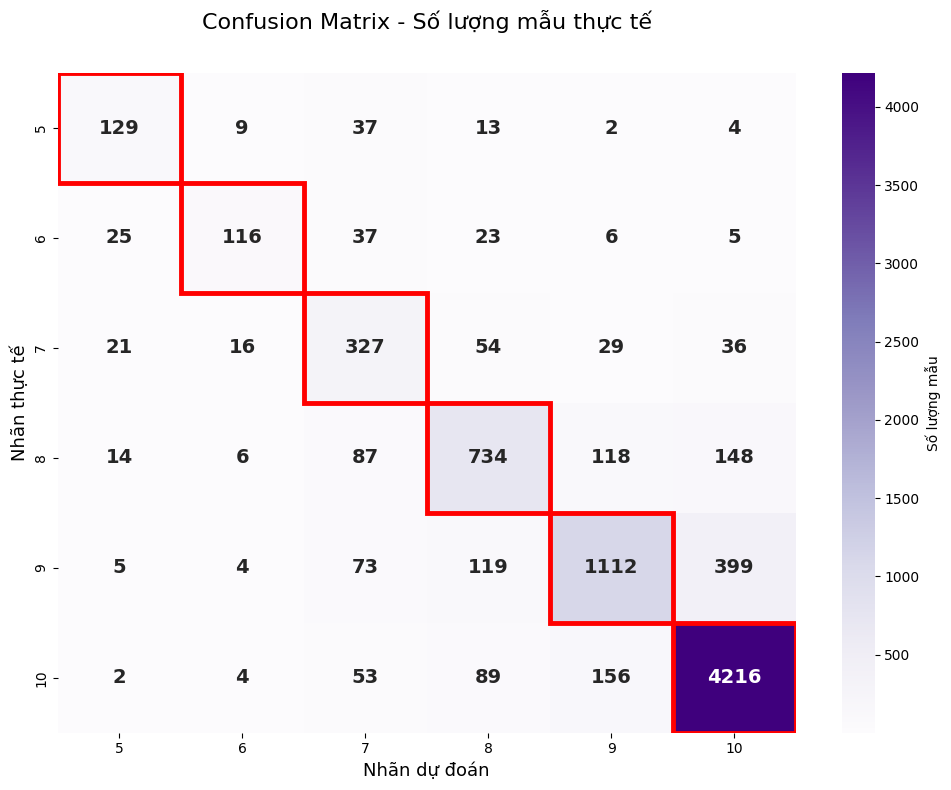

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Giả sử bạn đã có
# test_labels, test_preds là numpy array hoặc list

cm = confusion_matrix(test_labels, test_preds)

# Tên lớp: tùy bạn chọn một trong hai cách
class_names = ['5', '6', '7', '8', '9', '10']           # kiểu điểm số
# class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4', 'Class 5']

plt.figure(figsize=(10, 8))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Purples',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 14, "weight": "bold"},
            cbar_kws={'label': 'Số lượng mẫu'})

# Highlight đường chéo
for i in range(len(class_names)):
    plt.gca().add_patch(plt.Rectangle((i, i), 1, 1,
                                      fill=False, edgecolor='red', lw=3.5, zorder=10))

plt.title('Confusion Matrix - Số lượng mẫu thực tế\n', fontsize=16, pad=15)
plt.ylabel('Nhãn thực tế', fontsize=13)
plt.xlabel('Nhãn dự đoán', fontsize=13)
plt.tight_layout()
plt.show()

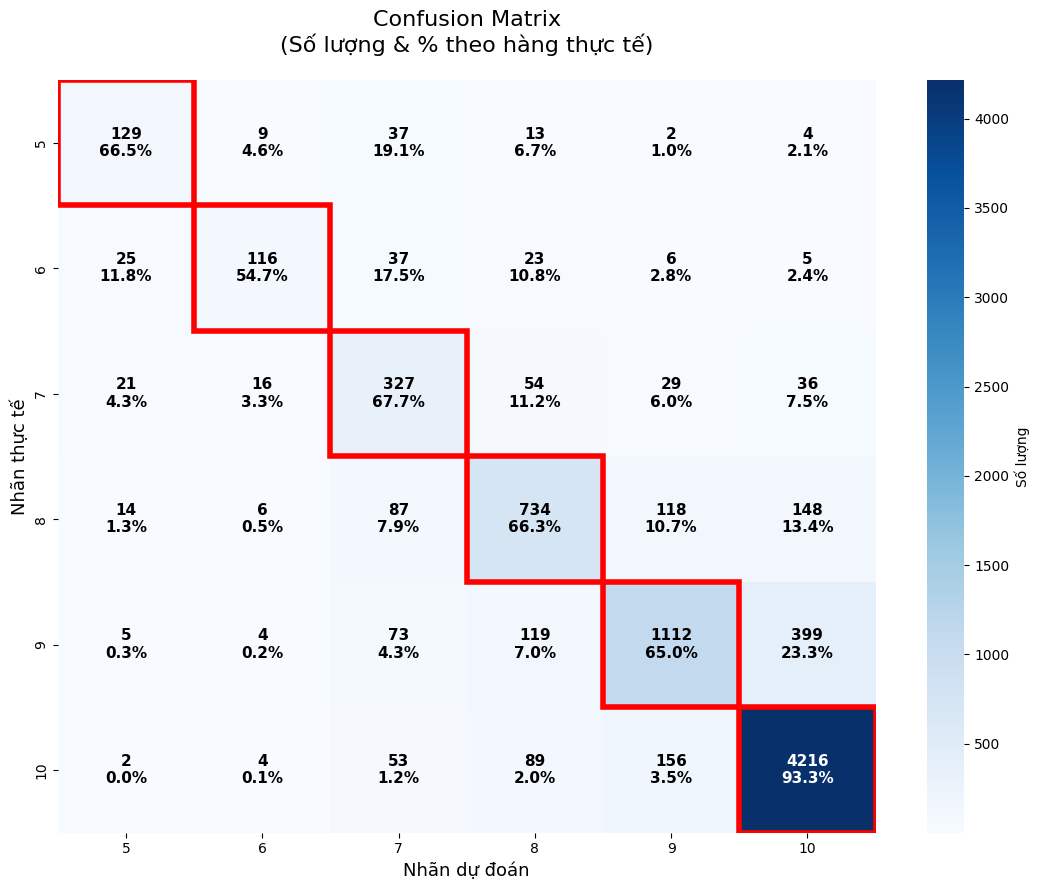

In [ ]:
import numpy as np

cm = confusion_matrix(test_labels, test_preds)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]  # chuẩn hóa theo hàng

class_names = ['5', '6', '7', '8', '9', '10']

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(cm, annot=False, cmap='Blues', ax=ax,
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Số lượng'})

# Vẽ text thủ công: số lượng + phần trăm
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        text = f"{cm[i,j]}\n{100*cm_percent[i,j]:.1f}%"
        ax.text(j+0.5, i+0.5, text,
                ha="center", va="center",
                color="white" if cm[i,j] > thresh else "black",
                fontsize=11, fontweight="bold")

ax.set_title("Confusion Matrix\n(Số lượng & % theo hàng thực tế)", fontsize=16, pad=20)
ax.set_ylabel("Nhãn thực tế", fontsize=13)
ax.set_xlabel("Nhãn dự đoán", fontsize=13)

# Đường chéo đỏ
for i in range(len(class_names)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor='red', lw=4, zorder=10))

plt.tight_layout()
plt.show()